# relu-tm: a Turing machine inside a width-4 ReLU network

This notebook walks through the package. A fixed ReLU network `N` simulates a Turing machine;
all of its hidden layers have **four neurons**. It is used as a **recurrent network**: its output
is fed back as its next input, x_{t+1} = N(x_t), one application per step of the machine. That is
an RNN without external input, whose cell is a deep width-4 network. The weights are computed from
the transition table (no training). Everything shown is checked against a classical emulator.

* Construction: [`docs/construction.md`](../docs/construction.md)
* Exact versus floating point: [`docs/numerics.md`](../docs/numerics.md)
* Papers: Bournez, Cohen & Wurm, *MFCS 2025* (the TM construction); Bournez, Cohen & Wurm,
  *Iterated Narrow Networks: Turing Completeness at Width 4 on Convex Input Spaces and the Complexity
  of Verification*, NeurIPS 2026 ([poster page](https://neurips.cc/virtual/2026/poster/148965)); and
  the companion paper Bournez, Cohen, Cohen & Wurm, FST/TCS 2026
  ([arXiv:2610.06092](https://arxiv.org/abs/2610.06092))

`relu-tm` implements the **simulation** of Theorem 3 of the NeurIPS paper (part (i)), in a width-4
variant with the state in its own register. It does **not** implement the certificate of Theorem 3
(part (ii)), so everything below concerns encoded inputs only.

Run it yourself: `pip install -e ".[notebook]"`, then `jupyter lab notebooks/tour.ipynb`.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import torch

from relu_tm import TuringMachine, build_network, encode, run, viz
from relu_tm.examples import binary_adder, busy_beaver, divisible_by_3_dfa, filler

viz.use_style()
RESULTS = Path("../experiments/results")
FIGURES = Path("../docs/figures")
FIGURES.mkdir(exist_ok=True)

## 1. A machine and its network

The 4-state busy beaver runs for 107 steps. `build_network` turns its transition table into a
network. `run` executes the classical emulator and the network side by side and decodes the
network's three registers after every step. The default backend is exact rational arithmetic;
`backend="dyadic"` computes the same numbers faster with integers, and `"float64"`/`"float32"`
use PyTorch.

In [2]:
tm = busy_beaver(4)
net = build_network(tm)
print(f"{tm.name}: {len(tm.states)} states, symbols {tm.symbols}")
print(f"network: width {net.width}, {net.depth} hidden layers, {net.n_parameters} parameters, base {net.layout.base}")

result = run(tm, network=net)
print(f"{result.steps} steps, network == emulator after every step: {result.agree}\n")
print(result.table(every=20))

BB(4): 5 states, symbols ('0', '1')
network: width 4, 52 hidden layers, 1051 parameters, base 4
107 steps, network == emulator after every step: True

 step  match  emulator                                  network
    0   ok    A: [0]                                    A: [0]
   20   ok    B: 1 1 1 0 1 [0]                          B: 1 1 1 0 1 [0]
   40   ok    C: 1 1 1 0 [1] 0 1                        C: 1 1 1 0 [1] 0 1
   60   ok    A: [0] 1 1 1 1 0 1 1 1 1                  A: [0] 1 1 1 1 0 1 1 1 1
   80   ok    A: 1 1 1 1 0 [0] 0 1 1 1 1                A: 1 1 1 1 0 [0] 0 1 1 1 1
  100   ok    A: 1 1 0 [0] 0 1 1 1 1 1 1 1 1            A: 1 1 0 [0] 0 1 1 1 1 1 1 1 1
  107   ok    Z: 1 [0] 1 1 1 1 1 1 1 1 1 1 1 1          Z: 1 [0] 1 1 1 1 1 1 1 1 1 1 1 1


## 2. Your own machine

Edit the table and run the cell. Moves are `L`, `R` or `S`; a missing entry or a halting state
stops the machine. This one replaces every `a` by `b` and vice versa, then halts on the blank.

In [3]:
mine = TuringMachine(
    {
        ("swap", "a"): ("swap", "b", "R"),
        ("swap", "b"): ("swap", "a", "R"),
        ("swap", "_"): ("done", "_", "S"),
    },
    start="swap",
    blank="_",
    halt_states={"done"},
)
mine_result = run(mine, "abba")
print(mine_result.table())
print("\nwidth", build_network(mine).width, "| agree:", mine_result.agree)

 step  match  emulator                                  network
    0   ok    swap: [a] b b a                           swap: [a] b b a
    1   ok    swap: b [b] b a                           swap: b [b] b a
    2   ok    swap: b a [b] a                           swap: b a [b] a
    3   ok    swap: b a a [a]                           swap: b a a [a]
    4   ok    swap: b a a b [_]                         swap: b a a b [_]
    5   ok    done: b a a b [_]                         done: b a a b [_]

width 4 | agree: True


## 3. The tape over time

Left: the tape **decoded from the network's registers** after every step (time runs down; the dot
is the head). It is identical to the emulator's tape at all 107 steps. Right: what happens inside
the network during one step. The state register first absorbs the head symbol (`read`), jumps to
the code of the transition that applies (`table`), and is reset to the new state at the end
(`state`); the work neuron carries the intermediate ReLU values. This figure is also the README's
core figure.

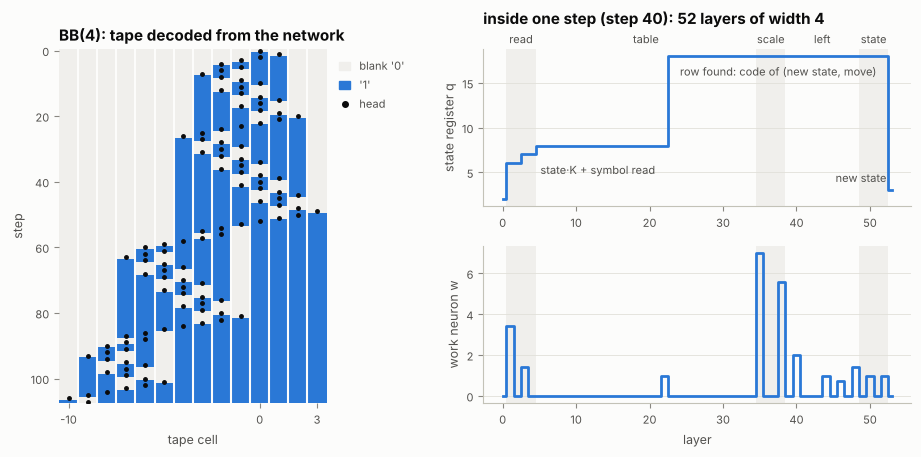

In [4]:
fig = viz.core_figure(tm, net, result.network, step=40)
fig.savefig(FIGURES / "core.png", dpi=150, bbox_inches="tight")
plt.show()

The same diagram for the binary adder computing `101 + 11` (symbols `0`, `1`, `+`):

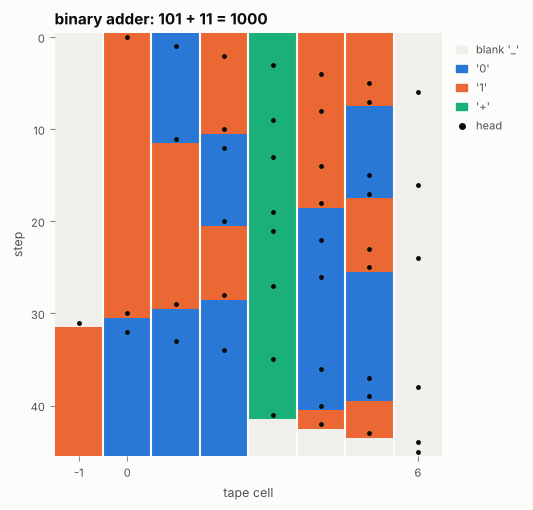

agree: True


In [5]:
adder = binary_adder()
adder_result = run(adder, "101+11")
fig, ax = plt.subplots(figsize=(5, 5.5))
viz.tape_diagram(adder, adder_result.network, ax, title="binary adder: 101 + 11 = 1000")
plt.show()
print("agree:", adder_result.agree)

## 4. Inside one step: the five passes

One application of the network consists of five passes (details in `docs/construction.md`):

1. **read**: pop the head symbol from `r` into the state register `q`;
2. **table**: one "hat" function per transition δ(state, symbol). The one that matches moves `q`
   to a code that records the new state and the move, and pushes the written symbol;
3. **scale**: gated scaling of `l` or `r` by 1/β, depending on the move;
4. **left**: for left moves, transfer the leading digit of `l` to `r`;
5. **state**: turn the code back into the plain state index.

Registers keep their values (they stay ≥ 0, so ReLU is the identity on them); only the work neuron
`w` computes non-linear things.

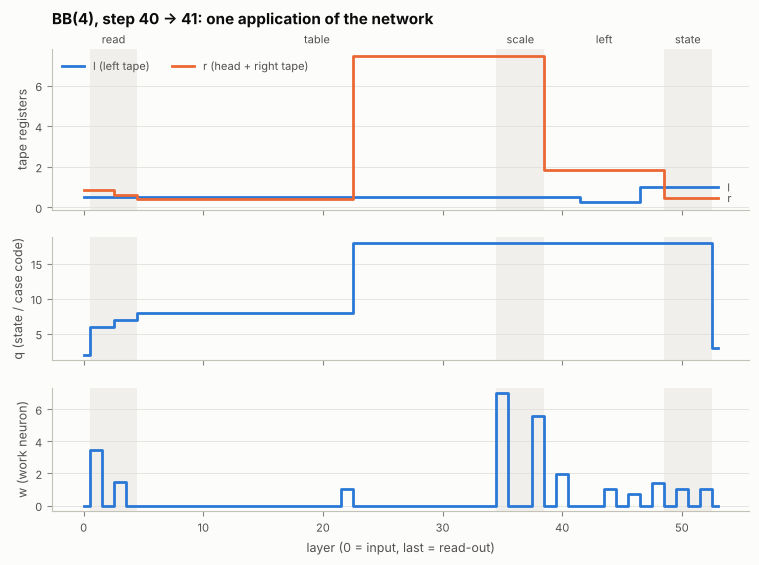

   #  w := ReLU(...)                      register updates / note
   1  4·r                                 q:=3·q  | read: gap 1, w = ReLU(beta r - 0)
   2  -w + 1                              read: gap 1, w = 1 - [digit >= 1]
   3  4·r + w - 2                         r:=r + 1/4·w - 1/4, q:=q - w + 1  | read: gap 2, w = ReLU(beta r - 1)
   4  -w + 1                              read: gap 2, w = 1 - [digit >= 3]
   5  -q + w - 1                          r:=4·r + 2·w - 2, q:=q - w + 1  | case 0 = (A, 0 (tail)): hat, part 1
   6  -q - 2·w + 1                        case 0: hat -> B,1,R
   7  -q - 26·w + 1                       l:=l + 3·w, q:=q + 26·w  | case 1 = (A, 0): hat, part 1
   8  -q - 2·w + 2                        case 1: hat -> B,1,R


In [6]:
fig, axes = plt.subplots(3, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": [1.3, 1, 1]})
viz.step_inside(net, result.vectors[40], axes, title="BB(4), step 40 → 41: one application of the network")
plt.show()
print("\n".join(net.program.listing().splitlines()[:9]))

## 5. Activations over all steps

A column is one **transition** δ(q, a) = (q′, a′, m) of the machine, i.e. one instruction
line *"in state q reading a: write a′, move m, go to q′"*. In pass 1 each transition has its own
hat function; the plot shows, for every step, which hat is 1. Exactly one transition fires per
step. Two details:
- The blank appears twice per state. `0 (tail)` is the never-written part of the tape, `0` is a
  blank the machine wrote. Both lead to the same transition, but the network can tell them apart.
- Halting states get an implicit "stay" transition. After the machine halts in `Z`, the network
  keeps applying it, so halted configurations are fixed points.

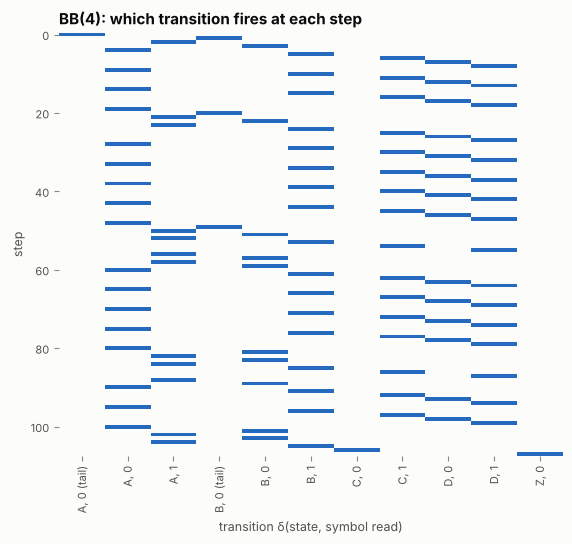

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
viz.transition_heatmap(net, result.vectors, ax, title="BB(4): which transition fires at each step")
plt.show()

## 6. Exact versus floating point

With exact rationals the network never fails. In floating point:

* in a **power-of-two base** all weights are dyadic and the float network is *bit-exact* until a
  register no longer fits into the mantissa - predicted exactly by ⌊(p−1−h)/m⌋ digits;
* in **other bases** the weights are rounded; the digit tests of the papers then amplify the
  rounding errors as soon as the machine reads its tape back, while **centred ramps**
  (`build_network(tm, ramps="centre")`) tolerate them.

The precision tests use two opposite workloads. The **filler** builds long registers in few
steps. The **zigzag** makes many steps on a short tape without repeating itself. The plots use
the measurements in `experiments/results/` (regenerate with `python experiments/numerics_step1.py`).

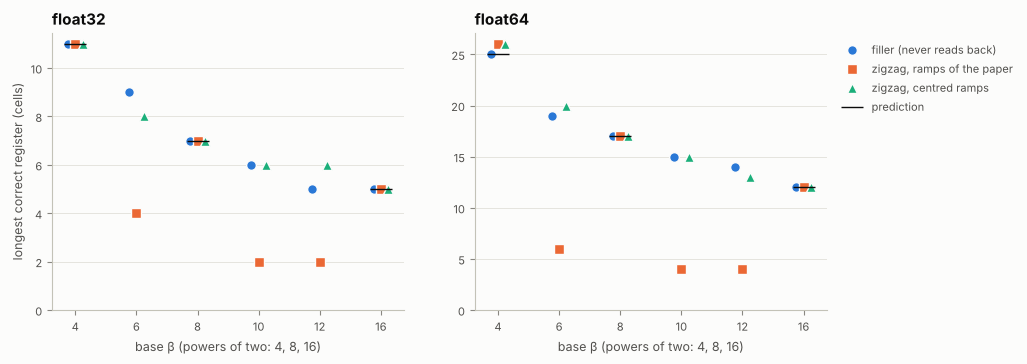

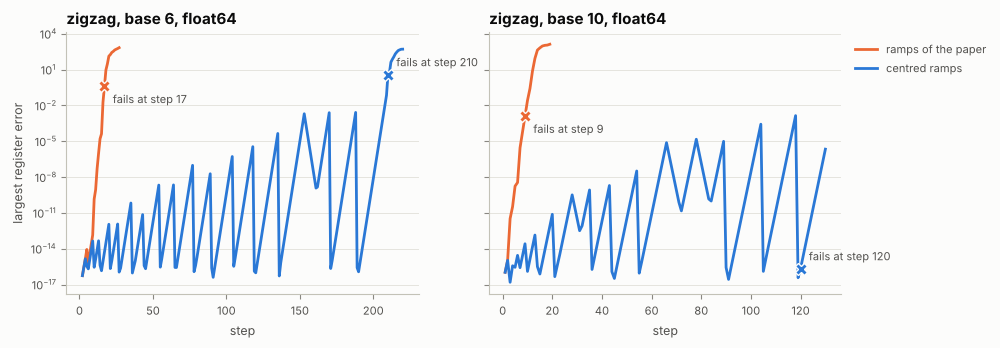

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
viz.capacity_plot(RESULTS / "numerics_step1_summary.csv", axes)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
viz.error_plot(RESULTS / "numerics_step1_trace.csv", axes=axes)
plt.show()

The sawtooth of the centred runs is the zigzag sweeping across its tape: every digit read
back multiplies the rounding error of the deeper digits by β, every turn starts a new sweep. The
run fails when a sweep is long enough for the error to reach the size of a digit. A live check
of the capacity:

In [9]:
for dtype in ("float32", "float64"):
    r = run(filler(), steps=40, backend=dtype)
    print(f"filler, base 4, {dtype}: exact up to {r.first_mismatch - 1} tape cells, wrong from step {r.first_mismatch}")

filler, base 4, float32: exact up to 11 tape cells, wrong from step 12
filler, base 4, float64: exact up to 25 tape cells, wrong from step 26


## 7. What this has to do with verification complexity

The NeurIPS 2026 paper studies **reachability** for iterated width-4 ReLU networks: given `N`,
two convex regions `Init` and `Acc` (for example axis-aligned boxes) and a time bound `T`, is there
an `x` in `Init` with `N^[t](x)` in `Acc` for some `t ≤ T`? This is the query of robustness
certification and of closed-loop verification.

The simulation makes the connection to computation explicit: iterating the width-4 step network
`N` gives a deep width-4 network `N^[T]`, and the question *"is there an input whose configuration
after `T` applications is accepting?"* lines up with classical complexity classes. Theorem 7 of the
paper:

| how the time bound is given | complexity of reachability | why |
|---|---|---|
| `T` in unary (`N^[T]` written out layer by layer) | NP-complete | x encodes a witness, `N` simulates a polynomial-time verifier |
| `T` in binary (only `N` and the number `T` are written down) | NEXP-complete | exponentially many steps fit into a polynomial description |
| no bound (∃ t) | RE-complete, undecidable | this is the halting problem |

The hardness holds on whole boxes, not only on valid encodings, because of the **certificate** of
Theorem 3: a fourth coordinate that flags every input whose simulation reads an invalid digit, so
points between encodings can never reach `Acc`. `relu-tm` does not implement the certificate, so its
network is only specified on encodings. The companion paper (FST/TCS 2026) proves NP-completeness for
single-input networks: width 4 on [0, 1], width 3 on the encoding set.

The demo below stays on the encoding set: a brute-force verifier
that asks *"how many binary inputs of length n are accepted within n + 1 steps?"* for the
divisible-by-3 automaton compiled to a Turing machine. PyTorch runs the network on all 2ⁿ
encodings at once; the work doubles with every extra input symbol - which, by NP-hardness, cannot
be avoided in general (unless P = NP).

In [10]:
tm3 = divisible_by_3_dfa().to_turing_machine()
net3 = build_network(tm3)
module = net3.to_torch(torch.float64)
accept = net3.layout.state_index("ACCEPT")

print(" n   candidates   accepted   expected   seconds")
for n in range(4, 15, 2):
    t0 = time.time()
    words = [format(i, f"0{n}b") for i in range(2**n)]
    x = torch.tensor(
        [[float(v) for v in encode(tm3.initial_configuration(w), net3.layout)] for w in words], dtype=torch.float64
    )
    with torch.no_grad():
        for _ in range(n + 1):
            x = module(x)
    accepted = int((x[:, 2].round() == accept).sum())
    expected = sum(int(w, 2) % 3 == 0 for w in words)
    print(f"{n:2d} {2**n:12d} {accepted:10d} {expected:10d} {time.time() - t0:9.3f}")

 n   candidates   accepted   expected   seconds


 4           16          6          6     0.967
 6           64         22         22     0.007
 8          256         86         86     0.018
10         1024        342        342     0.045


12         4096       1366       1366     0.210


14        16384       5462       5462     0.787


## Where to go next

* `relu-tm run <machine>` on the command line, with example names, bbchallenge strings or JFLAP /
  turingmachine.io files (`relu-tm list`, `relu-tm convert --help`);
* `relu-tm precision <machine> --base 6 --ramps centre` for the numerics;
* the tests in `tests/` show every guarantee in executable form (`pytest`).